In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Locate project root
ROOT = Path.cwd()

if ROOT.name.lower() in ["notebook", "notebooks"]:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"

splits = ["train", "validation", "test"]

print("Project directory:", ROOT)
print("Dataset directory:", DATA_DIR)

for split in splits:
    path = DATA_DIR / split
    print(f"{split}: {'Found' if path.exists() else 'Missing'}")

Project directory: C:\Users\admin\Downloads\plant-disease-classification
Dataset directory: C:\Users\admin\Downloads\plant-disease-classification\data
train: Found
validation: Found
test: Found


In [4]:
records = []

for split in splits:
    split_dir = DATA_DIR / split

    for class_dir in split_dir.iterdir():
        if not class_dir.is_dir():
            continue

        for image_path in class_dir.iterdir():
            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                records.append({
                    "split": split,
                    "class": class_dir.name,
                    "image_path": str(image_path)
                })

df = pd.DataFrame(records)

print("Total images:", len(df))

print("\nImages per split:")
print(df["split"].value_counts())

print("\nImages per disease class:")
print(df.groupby("class").size().sort_values(ascending=False))

Total images: 18160

Images per split:
split
train         12712
validation     2724
test           2724
Name: count, dtype: int64

Images per disease class:
class
Tomato___Tomato_Yellow_Leaf_Curl_Virus           5357
Tomato___Bacterial_spot                          2127
Tomato___Late_blight                             1909
Tomato___Septoria_leaf_spot                      1771
Tomato___Spider_mites Two-spotted_spider_mite    1676
Tomato___healthy                                 1591
Tomato___Target_Spot                             1404
Tomato___Early_blight                            1000
Tomato___Leaf_Mold                                952
Tomato___Tomato_mosaic_virus                      373
dtype: int64


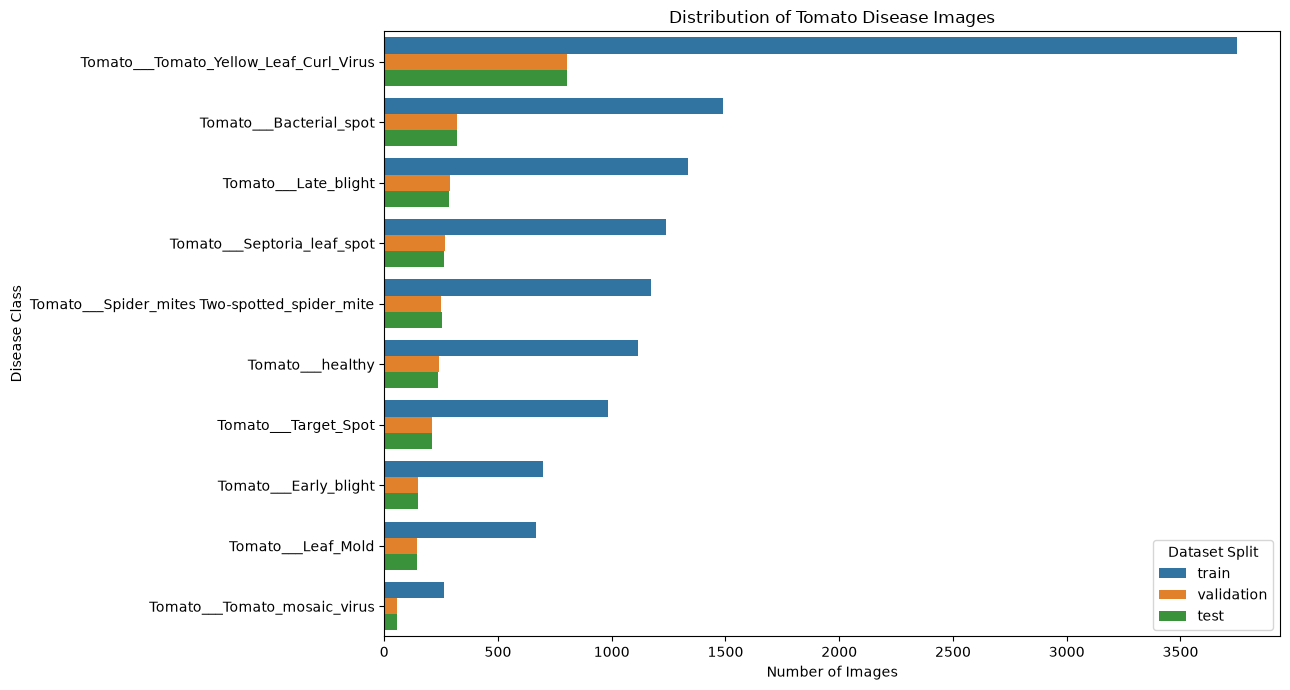

In [5]:
plt.figure(figsize=(13, 7))

sns.countplot(
    data=df,
    y="class",
    hue="split",
    order=df["class"].value_counts().index
)

plt.title("Distribution of Tomato Disease Images")
plt.xlabel("Number of Images")
plt.ylabel("Disease Class")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

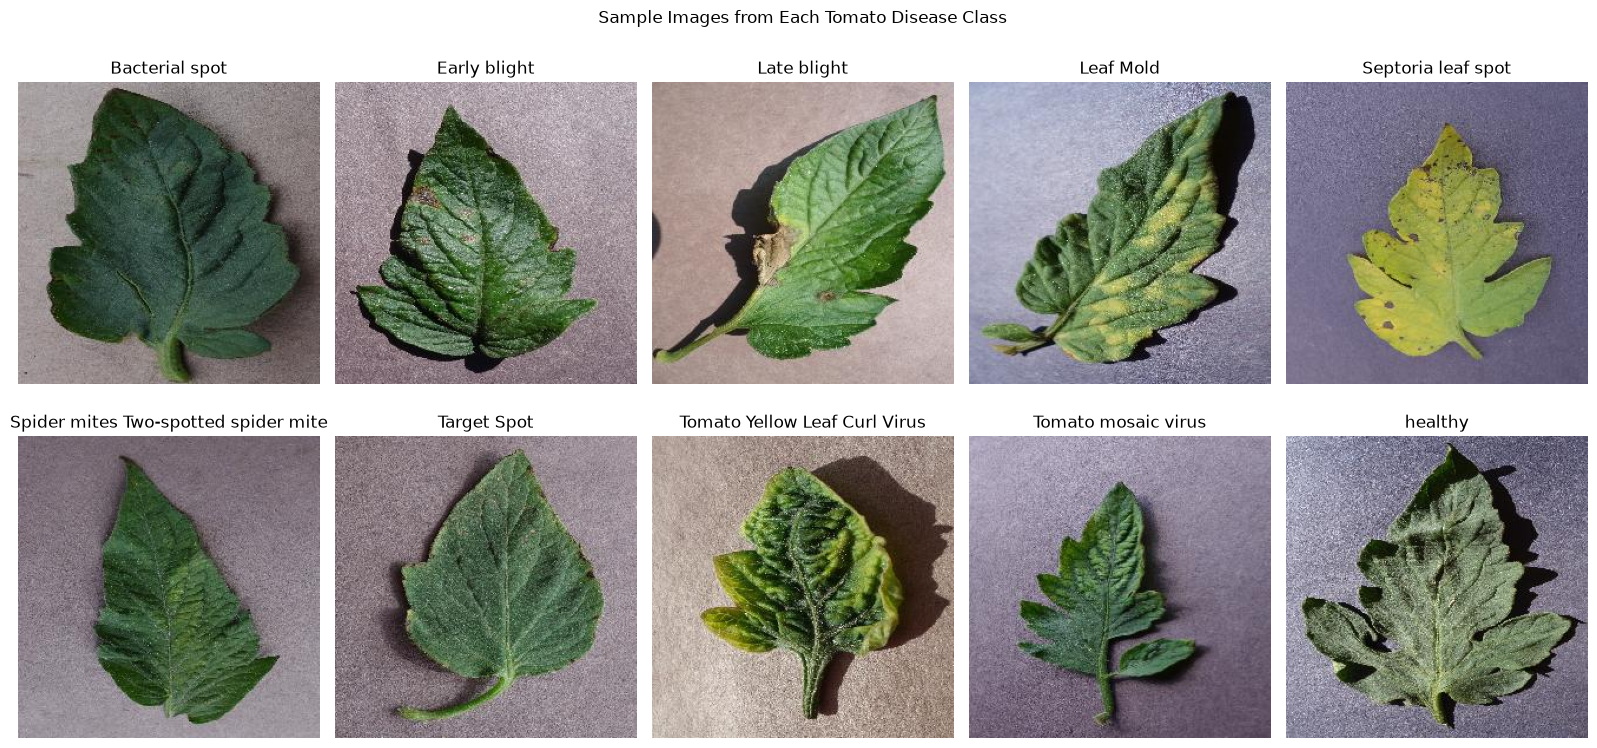

In [9]:
class_names = sorted(df["class"].unique())

fig, axes = plt.subplots(2, 5, figsize=(16, 8))

for ax, class_name in zip(axes.flat, class_names):
    sample_path = df[df["class"] == class_name].iloc[0]["image_path"]

    image = Image.open(sample_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(class_name.replace("Tomato___", "").replace("_", " "))
    ax.axis("off")

plt.suptitle("Sample Images from Each Tomato Disease Class")
plt.tight_layout()
plt.show()

         width   height  aspect_ratio
count  18160.0  18160.0       18160.0
mean     256.0    256.0           1.0
std        0.0      0.0           0.0
min      256.0    256.0           1.0
25%      256.0    256.0           1.0
50%      256.0    256.0           1.0
75%      256.0    256.0           1.0
max      256.0    256.0           1.0


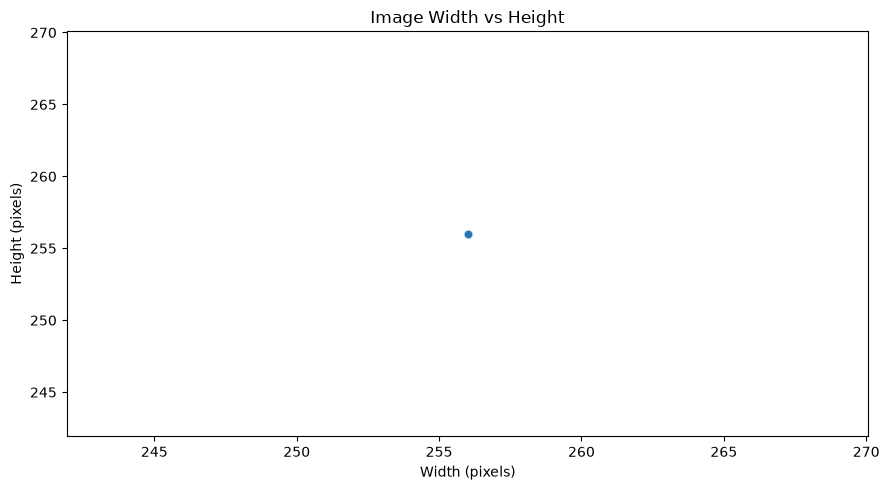

In [10]:
dimensions = []

for path in df["image_path"]:
    with Image.open(path) as image:
        width, height = image.size

        dimensions.append({
            "width": width,
            "height": height,
            "aspect_ratio": width / height
        })

dimensions_df = pd.DataFrame(dimensions)

print(dimensions_df.describe())

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=dimensions_df.sample(min(1000, len(dimensions_df)), random_state=42),
    x="width",
    y="height",
    alpha=0.5
)

plt.title("Image Width vs Height")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()
plt.show()

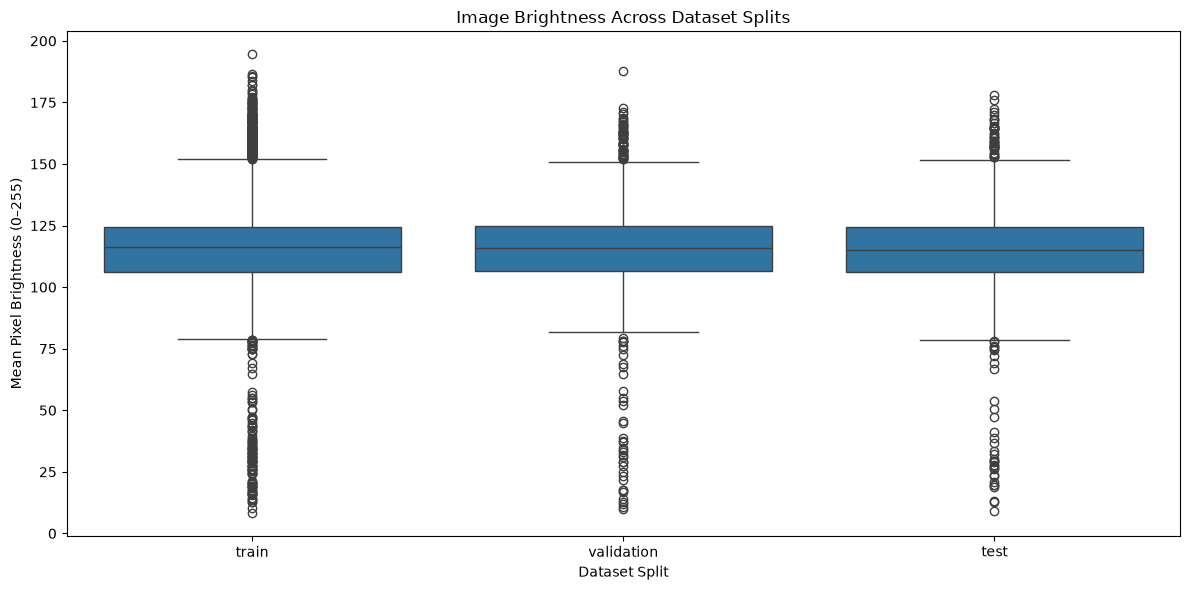

              count        mean        std       min         25%         50%  \
split                                                                          
test         2724.0  115.078778  16.375210  9.073990  105.946735  115.186317   
train       12712.0  115.713893  16.298109  8.246216  106.244476  116.116135   
validation   2724.0  115.482878  16.838628  9.820343  106.717670  115.998367   

                   75%         max  
split                               
test        124.455734  177.984314  
train       124.534634  194.555511  
validation  124.706779  187.847427  


In [11]:
brightness = []

for path in df["image_path"]:
    with Image.open(path) as image:
        grayscale = image.convert("L")
        brightness.append(np.asarray(grayscale).mean())

df["brightness"] = brightness

plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="split", y="brightness")

plt.title("Image Brightness Across Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Mean Pixel Brightness (0–255)")
plt.tight_layout()
plt.show()

print(df.groupby("split")["brightness"].describe())

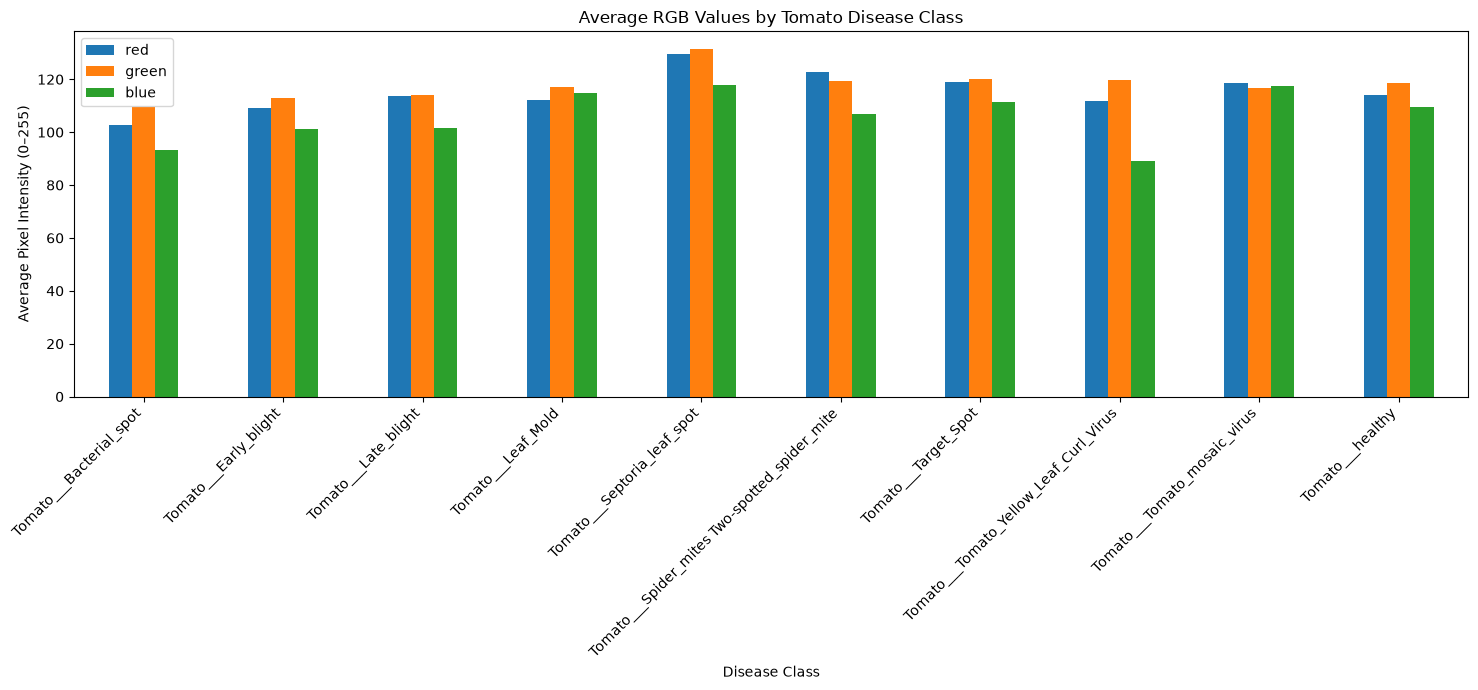

In [12]:
rgb_records = []

for class_name in class_names:
    class_images = df[df["class"] == class_name]

    samples = class_images.sample(
        min(500, len(class_images)),
        random_state=42
    )

    for path in samples["image_path"]:
        with Image.open(path) as image:
            rgb = np.asarray(image.convert("RGB").resize((64, 64)))

            rgb_records.append({
                "class": class_name,
                "red": rgb[:, :, 0].mean(),
                "green": rgb[:, :, 1].mean(),
                "blue": rgb[:, :, 2].mean()
            })

rgb_df = pd.DataFrame(rgb_records)

rgb_summary = rgb_df.groupby("class")[["red", "green", "blue"]].mean()

rgb_summary.plot(kind="bar", figsize=(15, 7))

plt.title("Average RGB Values by Tomato Disease Class")
plt.xlabel("Disease Class")
plt.ylabel("Average Pixel Intensity (0–255)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Exploratory Data Analysis — Findings and Observations

### 1. Dataset distribution
The dataset contains 18,160 tomato leaf images across 10 classification categories. It is divided into 12,712 training images, 2,724 validation images, and 2,724 testing images.

The class distribution is imbalanced. Tomato Yellow Leaf Curl Virus contains 5,357 images, while Tomato Mosaic Virus contains only 373 images. This imbalance may influence model performance and cause the model to favor majority classes.

**Decision:** Monitor class-specific precision, recall, and F1-score during evaluation. Consider class weighting during model training.

### 2. Image dimensions
All 18,160 images have dimensions of 256 × 256 pixels and an aspect ratio of 1:1.

**Decision:** Use a consistent 256 × 256 input size for the initial model. No image resizing is required for dimensional consistency.

### 3. Image brightness
The average brightness is approximately 115 across all dataset splits. The similar averages suggest that the splits have comparable overall brightness distributions.

**Decision:** Retain the original images and normalize pixel values during preprocessing.

### 4. RGB color characteristics
RGB analysis was performed using up to 500 sampled images per class. The analysis provides an overview of average color composition across disease categories.

**Observation:** Color characteristics may provide useful information for image classification, but average RGB values alone are insufficient to identify disease-specific features.

### Overall conclusion
The dataset is suitable for developing a tomato leaf disease classification model. However, class imbalance must be considered during training and evaluation. The consistent image dimensions simplify preprocessing, while brightness and color analyses provide useful baseline information about the dataset.


In [2]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: []


In [3]:
from pathlib import Path
import tensorflow as tf

# Locate the project and dataset directories
ROOT = Path.cwd()

if ROOT.name.lower() in ["notebook", "notebooks"]:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"

# Training configuration
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 32
SEED = 42

# Get class names from the training directory
class_names = sorted([
    folder.name
    for folder in (DATA_DIR / "train").iterdir()
    if folder.is_dir()
])

print("Number of classes:", len(class_names))
print("Classes:", class_names)


# Load training images
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    class_names=class_names,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=True,
    seed=SEED
)

# Load validation images
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "validation",
    class_names=class_names,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)

# Load test images
test_dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    class_names=class_names,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)

# Improve data-loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("\nDataset loading completed.")

Number of classes: 10
Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
Found 12712 files belonging to 10 classes.
Found 2724 files belonging to 10 classes.
Found 2724 files belonging to 10 classes.

Dataset loading completed.


In [4]:
# Get one batch of training images
images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("\nFirst 10 numerical labels:")
print(labels[:10].numpy())

print("\nClass mapping:")

for index, class_name in enumerate(class_names):
    print(f"{index}: {class_name}")

Image batch shape: (32, 256, 256, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 255.0

First 10 numerical labels:
[2 9 7 7 0 7 7 4 2 8]

Class mapping:
0: Tomato___Bacterial_spot
1: Tomato___Early_blight
2: Tomato___Late_blight
3: Tomato___Leaf_Mold
4: Tomato___Septoria_leaf_spot
5: Tomato___Spider_mites Two-spotted_spider_mite
6: Tomato___Target_Spot
7: Tomato___Tomato_Yellow_Leaf_Curl_Virus
8: Tomato___Tomato_mosaic_virus
9: Tomato___healthy


In [5]:
from tensorflow import keras
from tensorflow.keras import layers

# Define the CNN architecture
model = keras.Sequential([
    # Input
    layers.Input(shape=(256, 256, 3)),

    # Normalize pixel values
    layers.Rescaling(1./255),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Output: 10 classes
    layers.Dense(len(class_names), activation="softmax")
])

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 256, 256, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 256, 256, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 128, 128, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 128, 128, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 64, 64, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights using training labels
class_counts = np.zeros(len(class_names), dtype=np.int64)

for _, labels in train_dataset:
    class_counts += np.bincount(
        labels.numpy(),
        minlength=len(class_names)
    )

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=np.repeat(
        np.arange(len(class_names)),
        class_counts
    )
)

class_weights = {
    index: float(weight)
    for index, weight in enumerate(weights)
}

print("Class weights:")

for index, name in enumerate(class_names):
    print(f"{name}: {class_weights[index]:.3f}")

Class weights:
Tomato___Bacterial_spot: 0.854
Tomato___Early_blight: 1.816
Tomato___Late_blight: 0.951
Tomato___Leaf_Mold: 1.909
Tomato___Septoria_leaf_spot: 1.025
Tomato___Spider_mites Two-spotted_spider_mite: 1.084
Tomato___Target_Spot: 1.293
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 0.339
Tomato___Tomato_mosaic_virus: 4.870
Tomato___healthy: 1.141


In [8]:
from pathlib import Path

MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.00001
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=MODEL_DIR / "best_plant_disease_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [9]:
EPOCHS = 15

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/15


C:\Users\admin\Downloads\plant-disease-classification\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


398/398 ━━━━━━━━━━━━━━━━━━━━ 289s 721ms/step - accuracy: 0.3498 - loss: 1.8502 - val_accuracy: 0.4427 - val_loss: 1.4020 - learning_rate: 0.0010
Epoch 2/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 261s 655ms/step - accuracy: 0.5247 - loss: 1.3336 - val_accuracy: 0.5826 - val_loss: 1.1414 - learning_rate: 0.0010
Epoch 3/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 259s 649ms/step - accuracy: 0.6153 - loss: 1.0960 - val_accuracy: 0.6615 - val_loss: 0.9321 - learning_rate: 0.0010
Epoch 4/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 256s 642ms/step - accuracy: 0.6645 - loss: 0.9593 - val_accuracy: 0.7012 - val_loss: 0.8312 - learning_rate: 0.0010
Epoch 5/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 261s 656ms/step - accuracy: 0.7007 - loss: 0.8454 - val_accuracy: 0.7698 - val_loss: 0.6500 - learning_rate: 0.0010
Epoch 6/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 254s 638ms/step - accuracy: 0.7254 - loss: 0.7765 - val_accuracy: 0.7746 - val_loss: 0.6486 - learning_rate: 0.0010
Epoch 7/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 273s 686ms/step - accuracy: 0.7586 

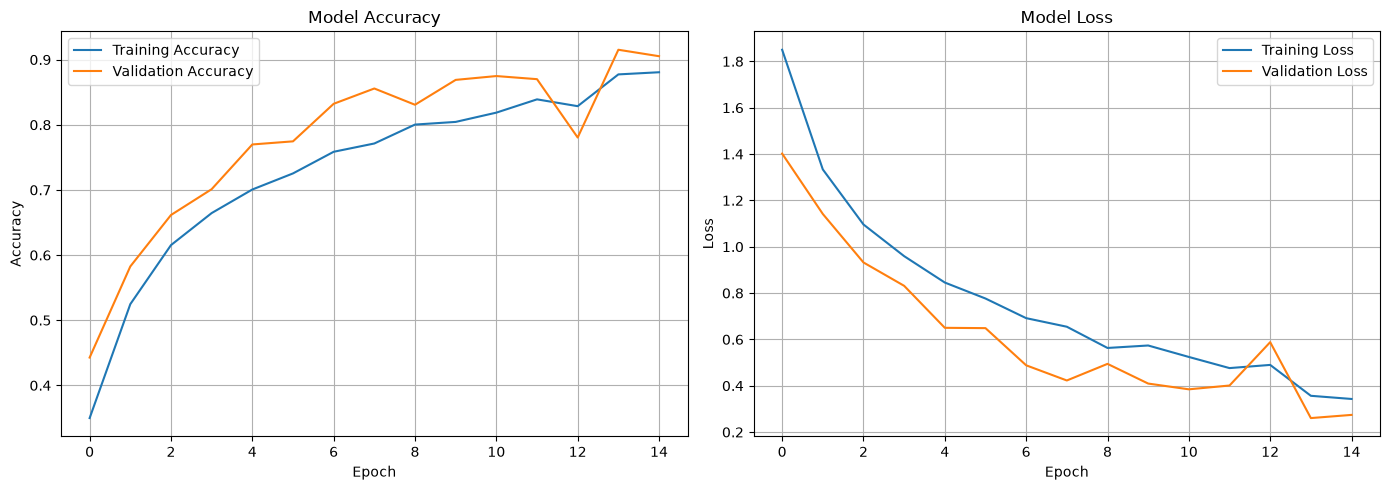

In [10]:
import matplotlib.pyplot as plt

history_dict = history.history

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_dict["accuracy"], label="Training Accuracy")
plt.plot(history_dict["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_dict["loss"], label="Training Loss")
plt.plot(history_dict["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
from tensorflow import keras
from pathlib import Path

MODEL_DIR = ROOT / "models"

best_model_path = MODEL_DIR / "best_plant_disease_model.keras"

model = keras.models.load_model(best_model_path)

print("Best model loaded successfully.")
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

Best model loaded successfully.
Model input: (None, 256, 256, 3)
Model output: (None, 10)


In [12]:
import numpy as np

# Predict probabilities for all test images
y_probabilities = model.predict(test_dataset)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_probabilities, axis=1)

# Extract actual labels from the test dataset
y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_dataset
])

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

print("First 10 actual labels:", y_true[:10])
print("First 10 predictions:", y_pred[:10])

86/86 ━━━━━━━━━━━━━━━━━━━━ 34s 378ms/step
Actual labels: (2724,)
Predicted labels: (2724,)
First 10 actual labels: [0 0 0 0 0 0 0 0 0 0]
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

balanced_acc = balanced_accuracy_score(y_true, y_pred)

print("MODEL EVALUATION RESULTS")
print("-" * 40)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Precision:         {precision:.4f}")
print(f"Recall:            {recall:.4f}")
print(f"F1-score:          {f1:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

MODEL EVALUATION RESULTS
----------------------------------------
Accuracy:          0.9082
Precision:         0.9132
Recall:            0.9082
F1-score:          0.9095
Balanced Accuracy: 0.9070

CLASSIFICATION REPORT
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.91      0.95      0.93       319
                        Tomato___Early_blight       0.70      0.87      0.78       150
                         Tomato___Late_blight       0.89      0.83      0.86       286
                           Tomato___Leaf_Mold       0.85      0.95      0.90       143
                  Tomato___Septoria_leaf_spot       0.95      0.89      0.92       265
Tomato___Spider_mites Two-spotted_spider_mite       0.83      0.88      0.86       252
                         Tomato___Target_Spot       0.89      0.89      0.89       211
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.97      0.93      0.95       8

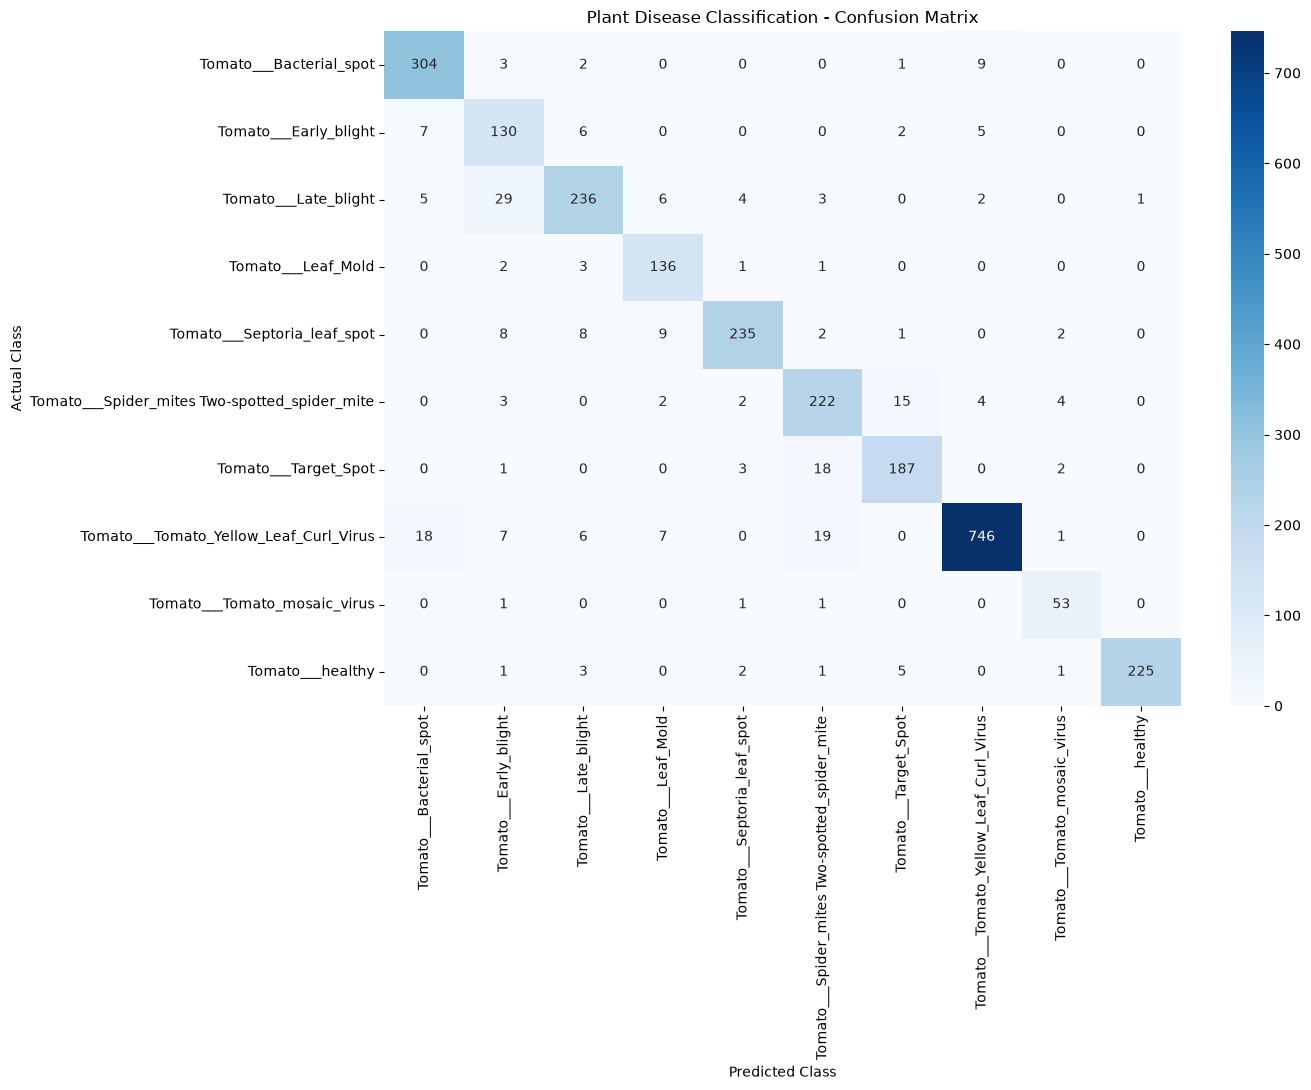

In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Plant Disease Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
import json

final_model_path = MODEL_DIR / "plant_disease_model.keras"

model.save(final_model_path)

class_names_path = MODEL_DIR / "class_names.json"

with open(class_names_path, "w") as file:
    json.dump(class_names, file, indent=4)

print("Final model saved:", final_model_path)
print("Class names saved:", class_names_path)

Final model saved: C:\Users\admin\Downloads\plant-disease-classification\models\plant_disease_model.keras
Class names saved: C:\Users\admin\Downloads\plant-disease-classification\models\class_names.json


## Model Evaluation Findings

The custom CNN achieved 90.82% test accuracy on 2,724
previously unseen images.

Evaluation metrics:
- Accuracy: 90.82%
- Weighted Precision: 91.32%
- Weighted Recall: 90.82%
- Weighted F1-score: 90.95%
- Balanced Accuracy: 90.70%

The model performed particularly well on:
- Healthy leaves (F1: 0.97)
- Tomato Yellow Leaf Curl Virus (F1: 0.95)
- Bacterial spot (F1: 0.93)

Areas requiring improvement:
- Early blight (F1: 0.78)
- Late blight (F1: 0.86)
- Spider mites (F1: 0.86)

The confusion matrix shows misclassification between
visually similar disease categories, particularly
Early blight and Late blight.

Conclusion:
The baseline CNN demonstrates good classification
performance, but further optimization and model
interpretability analysis are required.

In [23]:
from tensorflow.keras import layers

last_conv_layer = next(
    layer for layer in reversed(model.layers)
    if isinstance(layer, layers.Conv2D)
)

print("Last convolutional layer:", last_conv_layer.name)

Last convolutional layer: conv2d_2


In [28]:
def generate_gradcam(image, model, last_conv_layer):

    # Reconstruct a Functional model using existing trained layers
    inputs = keras.Input(shape=(256, 256, 3))

    x = inputs
    conv_outputs = None

    for layer in model.layers:
        x = layer(x)

        if layer.name == last_conv_layer.name:
            conv_outputs = x

    if conv_outputs is None:
        raise ValueError("Convolutional layer not found.")

    grad_model = keras.Model(
        inputs=inputs,
        outputs=[conv_outputs, x]
    )

    # Calculate gradients
    with tf.GradientTape() as tape:

        features, predictions = grad_model(
            image,
            training=False
        )

        predicted_class = tf.argmax(predictions[0])

        class_score = predictions[:, predicted_class]

    gradients = tape.gradient(class_score, features)

    # Calculate importance weights
    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    # Generate heatmap
    features = features[0]

    heatmap = tf.reduce_sum(
        features * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return (
        heatmap.numpy(),
        int(predicted_class.numpy()),
        float(predictions[0][predicted_class].numpy())
    )

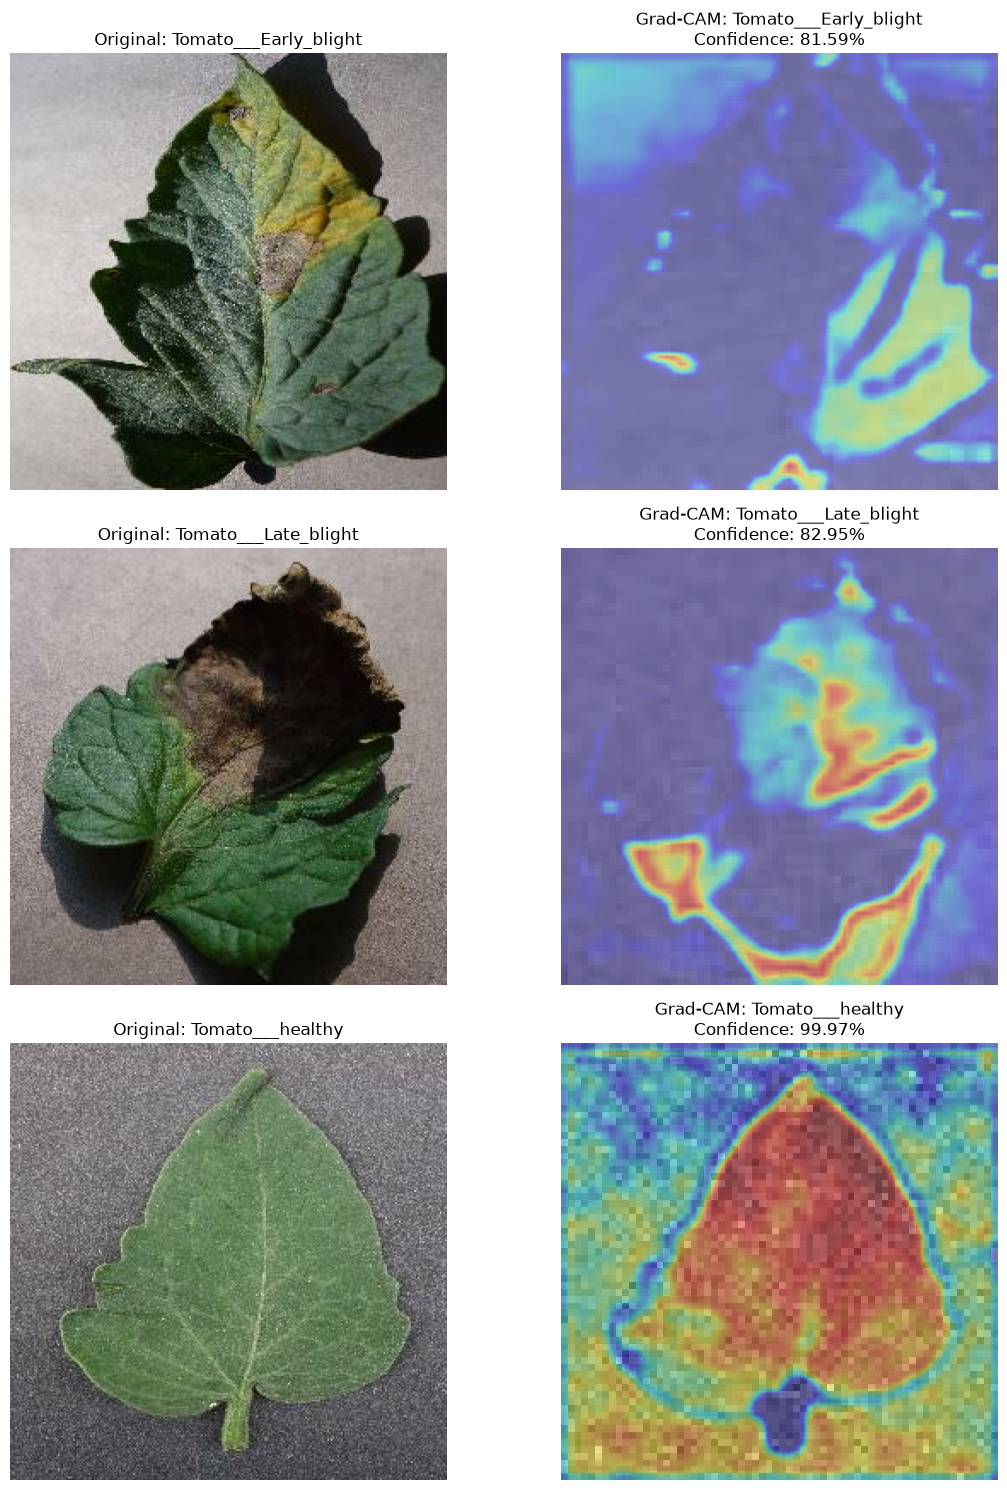

In [29]:
import matplotlib.pyplot as plt
import numpy as np

target_classes = [
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___healthy"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 15)
)

for row, target_class in enumerate(target_classes):

    class_index = class_names.index(target_class)

    # Prefer a correctly classified example
    matching_indices = np.where(
        (y_true == class_index) &
        (y_pred == class_index)
    )[0]

    if len(matching_indices) == 0:
        matching_indices = np.where(
            y_true == class_index
        )[0]

    sample_index = int(matching_indices[0])

    # Retrieve its batch without loading the whole dataset
    batch_index = sample_index // BATCH_SIZE
    position = sample_index % BATCH_SIZE

    batch_images, _ = next(
        iter(test_dataset.skip(batch_index).take(1))
    )

    image = batch_images[position:position + 1]

    # Generate Grad-CAM
    heatmap, predicted_index, confidence = generate_gradcam(
        image,
        model,
        last_conv_layer
    )

    original_image = image[0].numpy().astype("uint8")

    axes[row, 0].imshow(original_image)
    axes[row, 0].set_title(
        f"Original: {target_class}"
    )

    axes[row, 1].imshow(original_image)
    axes[row, 1].imshow(
        heatmap,
        cmap="jet",
        alpha=0.4,
        interpolation="bilinear"
    )

    axes[row, 1].set_title(
        f"Grad-CAM: {class_names[predicted_index]}\n"
        f"Confidence: {confidence:.2%}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## Model Interpretability Using Grad-CAM

### Objective
Grad-CAM (Gradient-weighted Class Activation Mapping) was implemented to interpret the predictions made by the custom CNN. It generates heatmaps that highlight image regions influential to the model's classification decisions.

### Interpretations

**1. Early Blight**

The heatmap showed localized activation over specific regions of the leaf. This indicates that the model relies on particular spatial features when classifying Early blight. Where these regions overlap with visible lesions, they may represent relevant disease-related visual patterns.

**2. Late Blight**

The heatmap showed concentrated activation in particular leaf regions, suggesting that the model uses localized visual information when distinguishing Late blight from other classes.

**3. Healthy Leaves**

The heatmap showed localized activation on the leaf image. This suggests that the model uses specific visual characteristics of healthy leaves when predicting the healthy class.

### Conclusion

Grad-CAM provided visual explanations of the CNN's classification decisions by highlighting influential image regions. The visualizations demonstrate that the model's predictions are associated with spatially localized image features.

These explanations provide insight into model behavior but do not independently establish that the highlighted regions correspond to specific biological disease symptoms.

In [8]:

# Data augmentation layers
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

# Optimized CNN architecture
optimized_model = keras.Sequential([
    layers.Input(shape=(256, 256, 3)),

    data_augmentation,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(len(class_names), activation="softmax")
])

# Compile with a lower learning rate
optimized_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

optimized_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 256, 256, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 256, 256, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 256, 256, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 128, 128, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 128, 128, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 64, 64, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=MODEL_DIR / "optimized_plant_disease_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]


In [10]:

optimized_history = optimized_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=12,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/12


C:\Users\admin\Downloads\plant-disease-classification\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


398/398 ━━━━━━━━━━━━━━━━━━━━ 0s 726ms/step - accuracy: 0.2876 - loss: 1.9897
Epoch 1: val_loss improved from None to 2.49649, saving model to C:\Users\admin\Downloads\plant-disease-classification\models\optimized_plant_disease_model.keras

Epoch 1: finished saving model to C:\Users\admin\Downloads\plant-disease-classification\models\optimized_plant_disease_model.keras
398/398 ━━━━━━━━━━━━━━━━━━━━ 315s 786ms/step - accuracy: 0.2876 - loss: 1.9897 - val_accuracy: 0.2779 - val_loss: 2.4965 - learning_rate: 5.0000e-04
Epoch 2/12
398/398 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.4692 - loss: 1.4808
Epoch 2: val_loss did not improve from 2.49649
398/398 ━━━━━━━━━━━━━━━━━━━━ 319s 800ms/step - accuracy: 0.4692 - loss: 1.4808 - val_accuracy: 0.3029 - val_loss: 3.4228 - learning_rate: 5.0000e-04
Epoch 3/12
398/398 ━━━━━━━━━━━━━━━━━━━━ 0s 735ms/step - accuracy: 0.5508 - loss: 1.2492
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.

Epoch 3: val_loss did not impr

In [11]:

print("Class weights:")
for index, class_name in enumerate(class_names):
    print(f"{class_name}: {class_weights[index]:.4f}")


Class weights:
Tomato___Bacterial_spot: 0.8537
Tomato___Early_blight: 1.8160
Tomato___Late_blight: 0.9515
Tomato___Leaf_Mold: 1.9087
Tomato___Septoria_leaf_spot: 1.0252
Tomato___Spider_mites Two-spotted_spider_mite: 1.0837
Tomato___Target_Spot: 1.2932
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 0.3390
Tomato___Tomato_mosaic_virus: 4.8705
Tomato___healthy: 1.1411


In [12]:

# Evaluate baseline
baseline_results = baseline_model.evaluate(
    validation_dataset,
    verbose=1
)

# Load best optimized checkpoint
optimized_model = keras.models.load_model(
    MODEL_DIR / "optimized_plant_disease_model.keras"
)

# Evaluate optimized model
optimized_results = optimized_model.evaluate(
    validation_dataset,
    verbose=1
)

print("\nBASELINE")
print(f"Loss: {baseline_results[0]:.4f}")
print(f"Accuracy: {baseline_results[1]:.4f}")

print("\nOPTIMIZED")
print(f"Loss: {optimized_results[0]:.4f}")
print(f"Accuracy: {optimized_results[1]:.4f}")


86/86 ━━━━━━━━━━━━━━━━━━━━ 16s 178ms/step - accuracy: 0.9152 - loss: 0.2604
86/86 ━━━━━━━━━━━━━━━━━━━━ 16s 179ms/step - accuracy: 0.2779 - loss: 2.4965

BASELINE
Loss: 0.2604
Accuracy: 0.9152

OPTIMIZED
Loss: 2.4965
Accuracy: 0.2779


In [13]:

optimized_model_v2 = keras.Sequential([
    layers.Input(shape=(256, 256, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(len(class_names), activation="softmax")
])

optimized_model_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

optimized_model_v2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)              │ (None, 256, 256, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 256, 256, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 128, 128, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 128, 128, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 64, 64, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:

callbacks_v2 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=MODEL_DIR / "optimized_plant_disease_model_v2.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history_v2 = optimized_model_v2.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=12,
    class_weight=class_weights,
    callbacks=callbacks_v2
)


Epoch 1/12
398/398 ━━━━━━━━━━━━━━━━━━━━ 0s 589ms/step - accuracy: 0.3096 - loss: 1.9454
Epoch 1: val_loss improved from None to 1.57283, saving model to C:\Users\admin\Downloads\plant-disease-classification\models\optimized_plant_disease_model_v2.keras

Epoch 1: finished saving model to C:\Users\admin\Downloads\plant-disease-classification\models\optimized_plant_disease_model_v2.keras
398/398 ━━━━━━━━━━━━━━━━━━━━ 264s 635ms/step - accuracy: 0.3096 - loss: 1.9454 - val_accuracy: 0.3965 - val_loss: 1.5728 - learning_rate: 5.0000e-04
Epoch 2/12
398/398 ━━━━━━━━━━━━━━━━━━━━ 0s 618ms/step - accuracy: 0.4855 - loss: 1.4409
Epoch 2: val_loss improved from 1.57283 to 1.21375, saving model to C:\Users\admin\Downloads\plant-disease-classification\models\optimized_plant_disease_model_v2.keras

Epoch 2: finished saving model to C:\Users\admin\Downloads\plant-disease-classification\models\optimized_plant_disease_model_v2.keras
398/398 ━━━━━━━━━━━━━━━━━━━━ 264s 663ms/step - accuracy: 0.4855 - loss: 

In [15]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import numpy as np
import pandas as pd

# Load best version 2 checkpoint
optimized_model_v2 = keras.models.load_model(
    MODEL_DIR / "optimized_plant_disease_model_v2.keras"
)

def get_predictions(model, dataset):
    y_true = np.concatenate([
        labels.numpy() for _, labels in dataset
    ])

    probabilities = model.predict(dataset, verbose=1)
    y_pred = np.argmax(probabilities, axis=1)

    return y_true, y_pred

# Predictions
y_true, baseline_predictions = get_predictions(
    baseline_model, validation_dataset
)

_, v2_predictions = get_predictions(
    optimized_model_v2, validation_dataset
)

# Calculate metrics
def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

comparison = pd.DataFrame([
    calculate_metrics(y_true, baseline_predictions, "Baseline"),
    calculate_metrics(y_true, v2_predictions, "Optimized V2")
])

display(comparison.round(4))


86/86 ━━━━━━━━━━━━━━━━━━━━ 17s 184ms/step
86/86 ━━━━━━━━━━━━━━━━━━━━ 16s 190ms/step


,Model,Accuracy,Precision,Recall,F1-score
0,Baseline,0.9152,0.9183,0.9152,0.9161
1,Optimized V2,0.8605,0.8655,0.8605,0.8612


In [16]:

print(classification_report(
    y_true,
    v2_predictions,
    target_names=class_names,
    zero_division=0
))


                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.87      0.93      0.90       319
                        Tomato___Early_blight       0.65      0.76      0.70       150
                         Tomato___Late_blight       0.85      0.72      0.78       287
                           Tomato___Leaf_Mold       0.81      0.79      0.80       143
                  Tomato___Septoria_leaf_spot       0.75      0.87      0.81       266
Tomato___Spider_mites Two-spotted_spider_mite       0.76      0.79      0.78       251
                         Tomato___Target_Spot       0.79      0.74      0.76       210
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.96      0.95      0.96       803
                 Tomato___Tomato_mosaic_virus       0.92      0.96      0.94        56
                             Tomato___healthy       1.00      0.88      0.94       239

                                     accu


## Model Optimization Experiments

Two optimization experiments were conducted to investigate
whether data augmentation and learning-rate adjustments
could improve the baseline CNN.

### Experiment 1: Data Augmentation

Applied random horizontal flipping, rotation, zooming,
and contrast adjustments. The learning rate was reduced
to 0.0005.

Results:
- Validation accuracy: 27.79%
- Validation loss: 2.4965

The model showed poor generalization. Training accuracy
increased while validation performance remained low.

### Experiment 2: Without Data Augmentation

Retained the original CNN architecture and class weights,
removed augmentation, and used a learning rate of 0.0005.

Results:
- Validation accuracy: 86.05%
- Precision: 86.55%
- Recall: 86.05%
- F1-score: 86.12%

This experiment improved substantially over Experiment 1,
but did not outperform the baseline.

### Final Optimization Decision

The baseline model was retained because it achieved
the best validation performance:

- Accuracy: 91.52%
- Precision: 91.83%
- Recall: 91.52%
- F1-score: 91.61%

The experiments demonstrate the importance of validating
optimization strategies instead of assuming that additional
complexity always improves model performance.

In [17]:

import shutil

production_model_path = MODEL_DIR / "plant_disease_model.keras"

# Copy the best baseline checkpoint
shutil.copy2(
    MODEL_DIR / "best_plant_disease_model.keras",
    production_model_path
)

print("Production candidate selected.")
print("Model:", production_model_path)


Production candidate selected.
Model: C:\Users\admin\Downloads\plant-disease-classification\models\plant_disease_model.keras


In [19]:

production_model = keras.models.load_model(
    production_model_path
)

test_loss, test_accuracy = production_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Final test accuracy: {test_accuracy:.4f}")
print(f"Final test loss: {test_loss:.4f}")

86/86 ━━━━━━━━━━━━━━━━━━━━ 18s 196ms/step - accuracy: 0.9082 - loss: 0.2677
Final test accuracy: 0.9082
Final test loss: 0.2677


In [20]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Generate predictions from the selected production model
y_test = np.concatenate([
    labels.numpy() for _, labels in test_dataset
])

test_probabilities = production_model.predict(
    test_dataset,
    verbose=1
)

y_test_pred = np.argmax(test_probabilities, axis=1)

print("Actual labels:", y_test.shape)
print("Predicted labels:", y_test_pred.shape)
print("Prediction probabilities:", test_probabilities.shape)


86/86 ━━━━━━━━━━━━━━━━━━━━ 17s 198ms/step
Actual labels: (2724,)
Predicted labels: (2724,)
Prediction probabilities: (2724, 10)


In [21]:

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred,
        average="weighted",
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred,
        average="weighted",
        zero_division=0
    ),
    "F1-score": f1_score(
        y_test, y_test_pred,
        average="weighted",
        zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test, y_test_pred
    )
}

test_metrics_df = pd.DataFrame(
    test_metrics.items(),
    columns=["Metric", "Score"]
)

display(test_metrics_df.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=class_names,
    zero_division=0
))


,Metric,Score
0,Accuracy,0.9082
1,Precision,0.9132
2,Recall,0.9082
3,F1-score,0.9095
4,Balanced Accuracy,0.9070



Classification Report:
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.91      0.95      0.93       319
                        Tomato___Early_blight       0.70      0.87      0.78       150
                         Tomato___Late_blight       0.89      0.83      0.86       286
                           Tomato___Leaf_Mold       0.85      0.95      0.90       143
                  Tomato___Septoria_leaf_spot       0.95      0.89      0.92       265
Tomato___Spider_mites Two-spotted_spider_mite       0.83      0.88      0.86       252
                         Tomato___Target_Spot       0.89      0.89      0.89       211
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.97      0.93      0.95       804
                 Tomato___Tomato_mosaic_virus       0.84      0.95      0.89        56
                             Tomato___healthy       1.00      0.95      0.97       238

                 

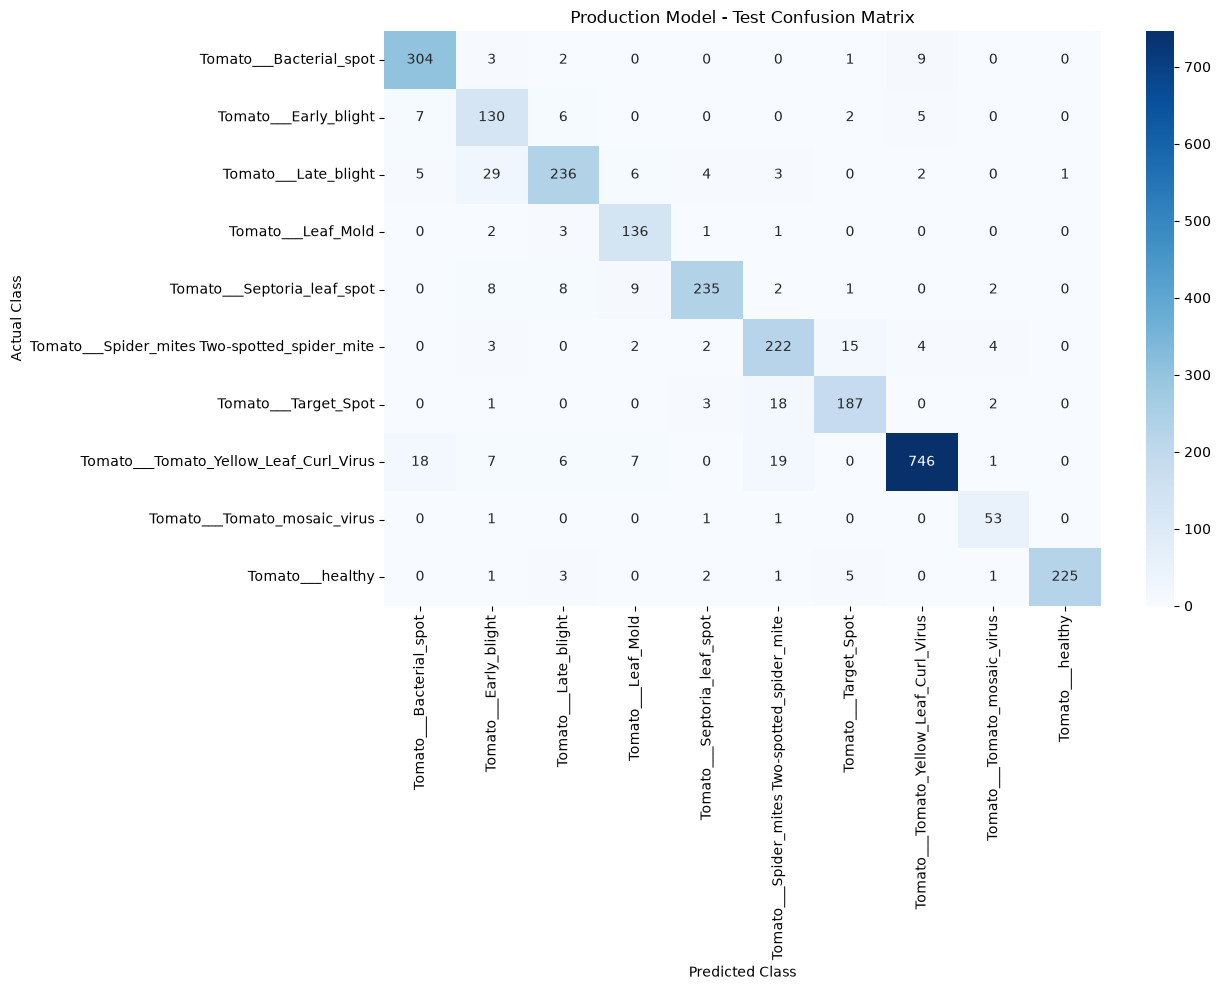

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Production Model - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
import json

with open(MODEL_DIR / "class_names.json", "r") as file:
    saved_class_names = json.load(file)

print("Number of classes:", len(saved_class_names))
print("Class names:")
for name in saved_class_names:
    print("-", name)

print("\nMatches training configuration:",
      saved_class_names == class_names)


### Incremental Model Retraining Experiment

The existing CNN was used as the starting model for incremental fine-tuning.

The retraining dataset contained 2,962 images, including 2,961 sampled from the original training dataset and 1 newly uploaded labeled image.

The model was fine-tuned for 3 epochs using the Adam optimizer with a learning rate of 0.00001.

**Results:**

| Metric | Before | After |
|---|---:|---:|
| Validation accuracy | 91.52% | 91.63% |
| Validation loss | 0.2604 | 0.2537 |

The candidate model satisfied the promotion criteria and replaced the production model. The previous production model was preserved as a backup.

The experiment demonstrates incremental fine-tuning, validation-based model promotion, and model version preservation.

The small performance improvement should not be interpreted as evidence of substantial learning from one additional image.
